In [ ]:
# Library
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from google.colab import drive
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
LATENT_DIM = 64
LEARNING_RATE = 0.001
EPOCHS = 20
BETA = 1.0

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [1]:
# CP
from pathlib import Path

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "vae"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Mounted at /content/drive
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/vae


In [ ]:
transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total Dataset:", len(full_dataset))
print("Training Set:", len(train_dataset))
print("Validation Set:", len(val_dataset))
print("Testing Set:", len(test_dataset))


Total Dataset: 70000
Training Set: 56000
Validation Set: 7000
Testing Set: 7000


In [ ]:
# VAE -> Architecture

class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std
        return z

    def forward(self, x):
        hidden = self.encoder(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        z = self.reparameterize(mu, logvar)

        reconstructed = self.decoder(z)
        reconstructed = reconstructed.view(-1, 1, 28, 28)

        return reconstructed, mu, logvar


vae = VAE(latent_dim=LATENT_DIM).to(DEVICE)

print(vae)


VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [ ]:
# Training

optimizer_vae = optim.Adam(
    vae.parameters(),
    lr=LEARNING_RATE
)

vae_train_losses = []
vae_val_losses = []
vae_train_mse = []
vae_val_mse = []
vae_train_kl = []
vae_val_kl = []
vae_epoch_times = []

best_vae_val_loss = float("inf")
best_vae_state = None

for epoch in range(EPOCHS):

    start_time = time.perf_counter()
    vae.train()

    total_train_loss = 0.0
    total_train_recon = 0.0
    total_train_kl = 0.0

    for images, _ in train_loader:

        images = images.to(DEVICE)
        batch_size = images.size(0)

        optimizer_vae.zero_grad()

        reconstructed, mu, logvar = vae(images)

        recon_loss = F.mse_loss(
            reconstructed,
            images,
            reduction="sum"
        ) / batch_size

        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        ) / batch_size

        loss = recon_loss + BETA * kl_loss

        loss.backward()
        optimizer_vae.step()

        total_train_loss += loss.item() * batch_size

        total_train_recon += (
            F.mse_loss(reconstructed, images).item()
            * batch_size
        )

        total_train_kl += kl_loss.item() * batch_size

    avg_train_loss = total_train_loss / len(train_dataset)
    avg_train_recon = total_train_recon / len(train_dataset)
    avg_train_kl = total_train_kl / len(train_dataset)

    vae.eval()

    total_val_loss = 0.0
    total_val_recon = 0.0
    total_val_kl = 0.0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)
            batch_size = images.size(0)

            reconstructed, mu, logvar = vae(images)

            recon_loss = F.mse_loss(
                reconstructed,
                images,
                reduction="sum"
            ) / batch_size

            kl_loss = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp()
            ) / batch_size

            loss = recon_loss + BETA * kl_loss

            total_val_loss += loss.item() * batch_size

            total_val_recon += (
                F.mse_loss(reconstructed, images).item()
                * batch_size
            )

            total_val_kl += kl_loss.item() * batch_size

    avg_val_loss = total_val_loss / len(val_dataset)
    avg_val_recon = total_val_recon / len(val_dataset)
    avg_val_kl = total_val_kl / len(val_dataset)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    vae_train_losses.append(avg_train_loss)
    vae_val_losses.append(avg_val_loss)

    vae_train_mse.append(avg_train_recon)
    vae_val_mse.append(avg_val_recon)

    vae_train_kl.append(avg_train_kl)
    vae_val_kl.append(avg_val_kl)

    vae_epoch_times.append(epoch_time)

    if avg_val_loss < best_vae_val_loss:
        best_vae_val_loss = avg_val_loss

        best_vae_state = {
            key: value.detach().cpu().clone()
            for key, value in vae.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Train MSE: {avg_train_recon:.6f} | "
        f"KL: {avg_train_kl:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

vae.load_state_dict(best_vae_state)

print("\nVAE Training Complete!")
print(f"Best Validation Loss: {best_vae_val_loss:.4f}")
print(f"Average Epoch Time: {np.mean(vae_epoch_times):.2f}s")

checkpoint_path = CHECKPOINT_DIR / "vae.pt"

torch.save(
    best_vae_state,
    checkpoint_path
)

print("Saved checkpoint:", checkpoint_path)

pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "train_loss": vae_train_losses,
    "val_loss": vae_val_losses,
    "train_mse": vae_train_mse,
    "val_mse": vae_val_mse,
    "train_kl": vae_train_kl,
    "val_kl": vae_val_kl,
    "epoch_time_s": vae_epoch_times
}).to_csv(
    OUTPUT_DIR / "loss_history.csv",
    index=False
)


Epoch [1/20] | Train Loss: 45.5275 | Val Loss: 36.4346 | Train MSE: 0.049851 | KL: 6.4447 | Time: 8.18s
Epoch [2/20] | Train Loss: 33.9948 | Val Loss: 31.6712 | Train MSE: 0.033104 | KL: 8.0412 | Time: 7.02s
Epoch [3/20] | Train Loss: 30.0141 | Val Loss: 29.4755 | Train MSE: 0.028781 | KL: 7.4497 | Time: 8.07s
Epoch [4/20] | Train Loss: 28.3263 | Val Loss: 27.9331 | Train MSE: 0.026771 | KL: 7.3378 | Time: 6.99s
Epoch [5/20] | Train Loss: 27.4818 | Val Loss: 27.4087 | Train MSE: 0.025589 | KL: 7.4201 | Time: 8.11s
Epoch [6/20] | Train Loss: 26.9313 | Val Loss: 26.9133 | Train MSE: 0.024765 | KL: 7.5157 | Time: 8.11s
Epoch [7/20] | Train Loss: 26.5807 | Val Loss: 26.5105 | Train MSE: 0.024210 | KL: 7.6003 | Time: 7.69s
Epoch [8/20] | Train Loss: 26.2688 | Val Loss: 26.3259 | Train MSE: 0.023768 | KL: 7.6351 | Time: 8.05s
Epoch [9/20] | Train Loss: 25.9987 | Val Loss: 26.1081 | Train MSE: 0.023395 | KL: 7.6567 | Time: 7.07s
Epoch [10/20] | Train Loss: 25.7923 | Val Loss: 25.8151 | Train 

In [ ]:

# VAE -> Test Evaluation

vae.eval()

total_squared_error = 0.0
total_pixels = 0

psnr_values = []
ssim_values = []
kl_values = []

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)

        hidden = vae.encoder(images)

        mu = vae.fc_mu(hidden)
        logvar = vae.fc_logvar(hidden)

        reconstructed = vae.decoder(mu)
        reconstructed = reconstructed.view(-1, 1, 28, 28)

        squared_error = (reconstructed - images) ** 2

        total_squared_error += squared_error.sum().item()
        total_pixels += images.numel()

        mse_per_image = squared_error.mean(dim=(1, 2, 3))

        psnr_batch = 10 * torch.log10(
            1.0 / mse_per_image.clamp_min(1e-10)
        )

        psnr_values.extend(
            psnr_batch.cpu().numpy()
        )

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):

            score = structural_similarity(
                original_np[i, 0],
                reconstructed_np[i, 0],
                data_range=1.0
            )

            ssim_values.append(score)

        kl = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp(),
            dim=1
        )

        kl_values.extend(kl.cpu().numpy())

vae_test_mse = total_squared_error / total_pixels
vae_test_psnr = float(np.mean(psnr_values))
vae_test_ssim = float(np.mean(ssim_values))
vae_test_kl = float(np.mean(kl_values))

print("VAE Test Results")
print(f"Test MSE  : {vae_test_mse:.6f}")
print(f"Test PSNR : {vae_test_psnr:.4f}")
print(f"Test SSIM : {vae_test_ssim:.6f}")
print(f"Test KL   : {vae_test_kl:.4f}")

pd.DataFrame([{
    "model": "VAE",
    "test_mse": vae_test_mse,
    "test_psnr": vae_test_psnr,
    "test_ssim": vae_test_ssim,
    "test_kl": vae_test_kl,
    "best_val_loss": best_vae_val_loss,
    "mean_epoch_time_s": float(np.mean(vae_epoch_times)),
    "latent_dim": LATENT_DIM,
    "beta": BETA,
    "epochs": EPOCHS,
    "seed": SEED
}]).to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False
)


VAE Test Results
Test MSE  : 0.017936
Test PSNR : 18.1290
Test SSIM : 0.631546
Test KL   : 8.0343


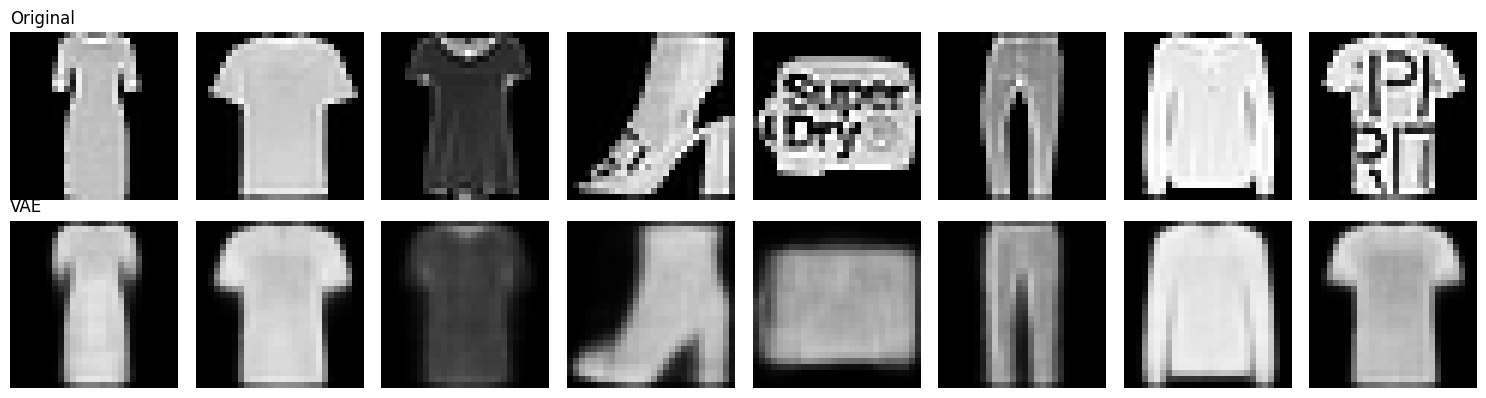

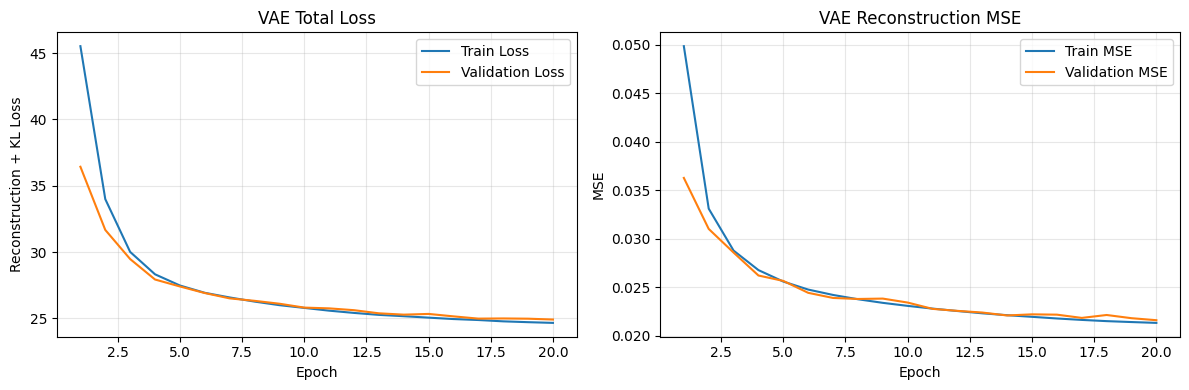

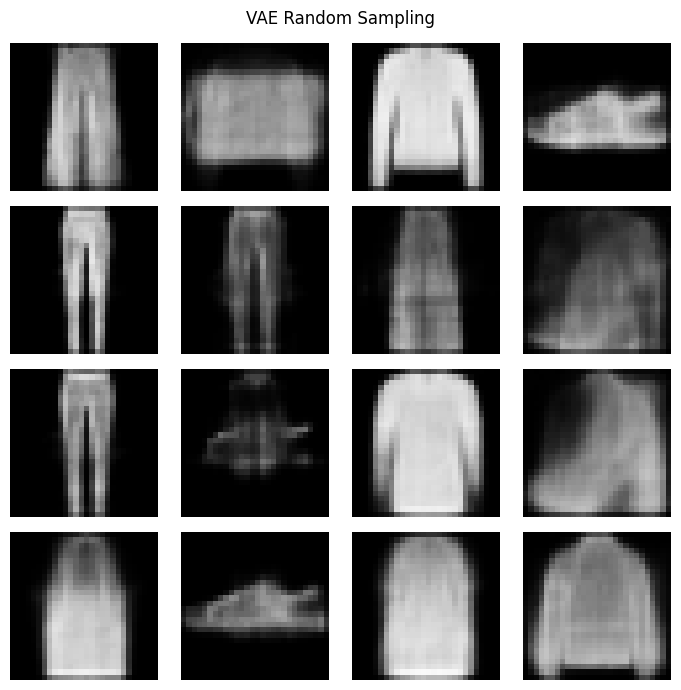

Saved images and CSV files to: /content/drive/MyDrive/Model_Comparison/outputs/vae


In [ ]:

# VAE -> Reconstruction

vae.eval()

comparison_images, comparison_labels = next(iter(test_loader))
comparison_images = comparison_images[:8].to(DEVICE)

with torch.no_grad():

    hidden = vae.encoder(comparison_images)
    mu = vae.fc_mu(hidden)

    reconstructed = vae.decoder(mu)
    reconstructed = reconstructed.view(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(15, 4))

for i in range(8):

    axes[0, i].imshow(
        comparison_images[i, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        reconstructed[i, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for row in range(2):
        axes[row, i].axis("off")

axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("VAE", loc="left")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# VAE -> Training Loss

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    range(1, EPOCHS + 1),
    vae_train_losses,
    label="Train Loss"
)

axes[0].plot(
    range(1, EPOCHS + 1),
    vae_val_losses,
    label="Validation Loss"
)

axes[0].set_title("VAE Total Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Reconstruction + KL Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    range(1, EPOCHS + 1),
    vae_train_mse,
    label="Train MSE"
)

axes[1].plot(
    range(1, EPOCHS + 1),
    vae_val_mse,
    label="Validation MSE"
)

axes[1].set_title("VAE Reconstruction MSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# VAE -> Random Sampling

with torch.no_grad():

    sample_generator = torch.Generator(device=DEVICE)
    sample_generator.manual_seed(SEED + 100)

    z = torch.randn(
        16, LATENT_DIM,
        device=DEVICE,
        generator=sample_generator
    )

    generated_images = vae.decoder(z).view(
        16, 1, 28, 28
    )

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_images[i, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

fig.suptitle("VAE Random Sampling")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "random_sampling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved images and CSV files to:", OUTPUT_DIR)
